In [ ]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")


# Разведочный анализ данных (EDA)

In [20]:
DATA_DIR = Path("../datasets")
x_train_raw = pd.read_csv(DATA_DIR / "data_train.csv", parse_dates=True, index_col=0)
x_test_raw = pd.read_csv(DATA_DIR / "data_test_small.csv", parse_dates=True, index_col=0)
y_train_raw = pd.read_csv(DATA_DIR / "target_train.csv", parse_dates=True, index_col=0)
y_test_raw = pd.read_csv(DATA_DIR / "target_test_small.csv", parse_dates=True, index_col=0)

In [21]:
x_train_raw.head()  # посмотрим на загруженный датасет

,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
datetime,,,,,,,,,,,,,,,,
2019-03-01 00:01:00,0.737538,0.478367,0.292816,0.644016,0.919471,0.884814,0.754800,0.413295,0.47192,0.677801,0.687535,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:02:00,0.738406,0.478977,0.292816,0.648557,0.919471,0.887129,0.752977,0.413295,0.47192,0.677801,0.688926,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:03:00,0.738985,0.478977,0.292816,0.647164,0.919471,0.887129,0.755444,0.413295,0.47192,0.677801,0.690316,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:04:00,0.739563,0.478977,0.292816,0.636938,0.919471,0.887129,0.754800,0.413295,0.47192,0.678079,0.692820,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:05:00,0.740431,0.477119,0.292816,0.635834,0.919471,0.887707,0.754156,0.413295,0.47192,0.678357,0.695601,0.498407,NaN,NaN,NaN,NaN


In [22]:
y_train_raw.head()

,target
Дата,
2019-03-13 17:00:00,0.123711
2019-03-13 21:00:00,0.319588
2019-03-14 01:00:00,0.255155
2019-03-14 05:00:00,0.319588
2019-03-14 09:00:00,0.159794


In [24]:
# посмотрим на количество пропусков в данных
for k in x_train_raw.keys():
    print(f"{k}:", x_train_raw[k].notna().sum(), "/", x_train_raw[k].size)
print("target:", y_train_raw["target"].notna().sum(), "/", y_train_raw["target"].size)

telemetry_0: 319529 / 319546
telemetry_1: 319530 / 319546
telemetry_2: 319530 / 319546
telemetry_3: 319530 / 319546
telemetry_4: 319413 / 319546
telemetry_5: 319529 / 319546
telemetry_6: 319530 / 319546
telemetry_7: 319530 / 319546
telemetry_8: 319530 / 319546
telemetry_9: 319530 / 319546
telemetry_10: 319530 / 319546
telemetry_11: 319530 / 319546
telemetry_12: 2098 / 319546
telemetry_13: 2098 / 319546
telemetry_14: 2098 / 319546
telemetry_15: 2098 / 319546
target: 1773 / 1773


<Axes: xlabel='Дата'>

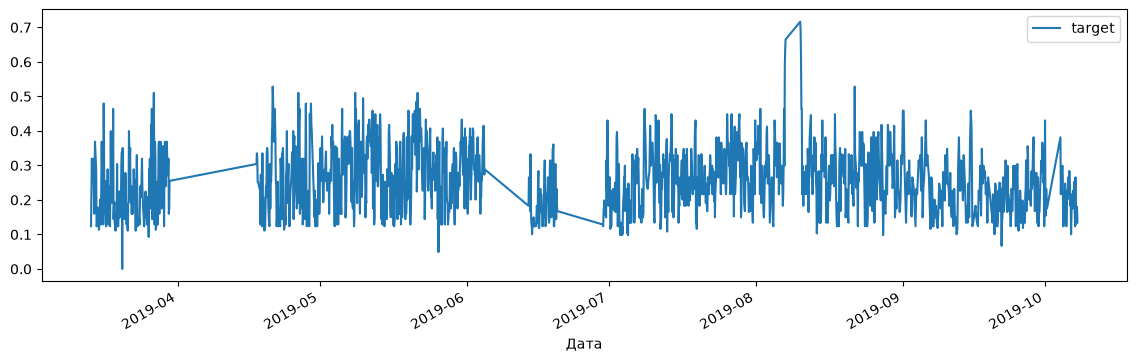

In [25]:
# посмотрим на таргеты
y_train_raw.plot(figsize=(14, 4))

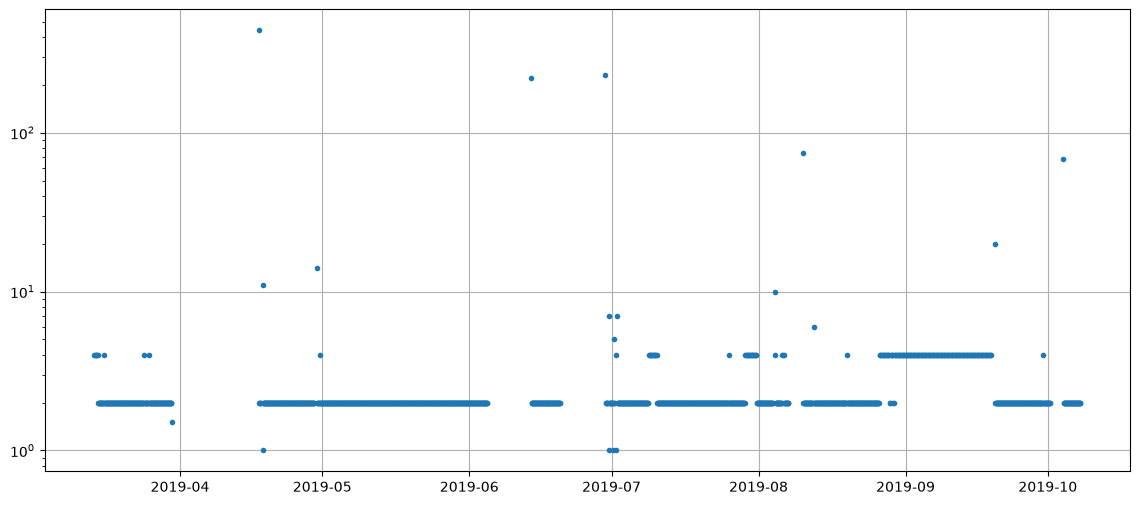

In [26]:
# картинка выше показывает, что временная сетка отличается
# посмотрим на временные шаги (в часах)
tsteps = y_train_raw.index.to_series().diff().dt.total_seconds().div(3600)
plt.figure(figsize=(14, 6))
plt.grid()
plt.yscale("log")
plt.plot(tsteps, ".")
plt.show()

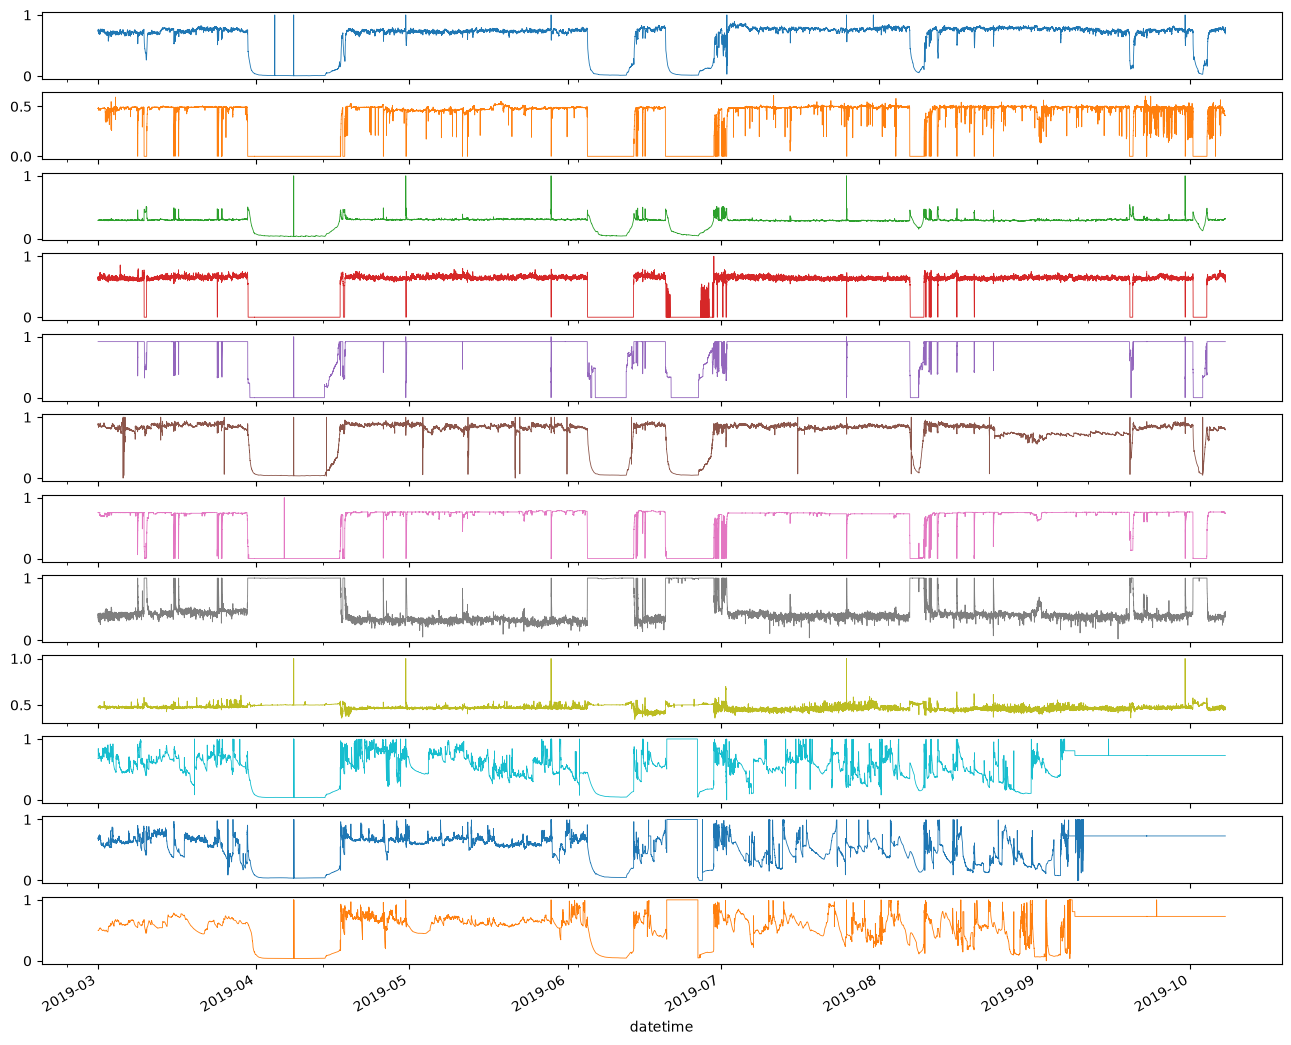

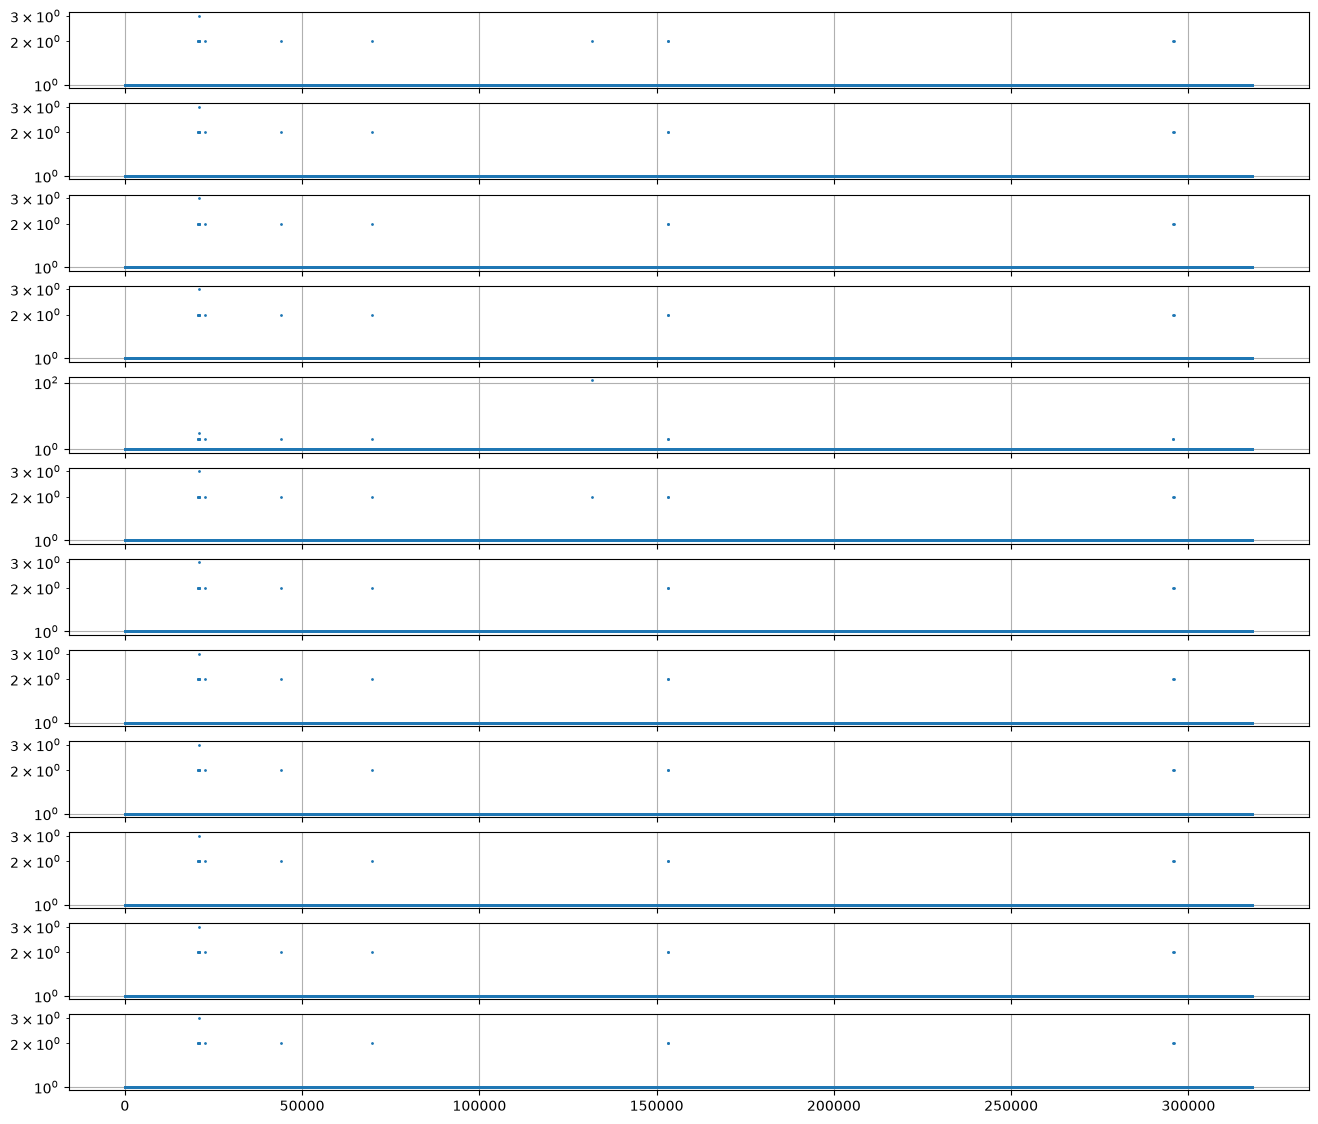

In [31]:
# построим часть фичей с небольшим количество пропусков
BASE_COLS = list(x_train_raw.keys())[:12]
x_train_raw[BASE_COLS].plot(subplots=True, figsize=(16, 14), sharex=True, lw=0.6, legend=False)
plt.show()

# построим временные шаги (в минутах)
fig, axes = plt.subplots(len(BASE_COLS), 1, figsize=(16, 14), sharex=True)
for ax, col in zip(axes, BASE_COLS):
    ts = pd.Series(x_train_raw.index[x_train_raw[col].notna()]).drop_duplicates().sort_values()
    tsteps = ts.diff().dt.total_seconds().div(60)
    ax.plot(tsteps.values, ".", ms=2)
    ax.set_yscale("log")
    ax.grid()
plt.show()

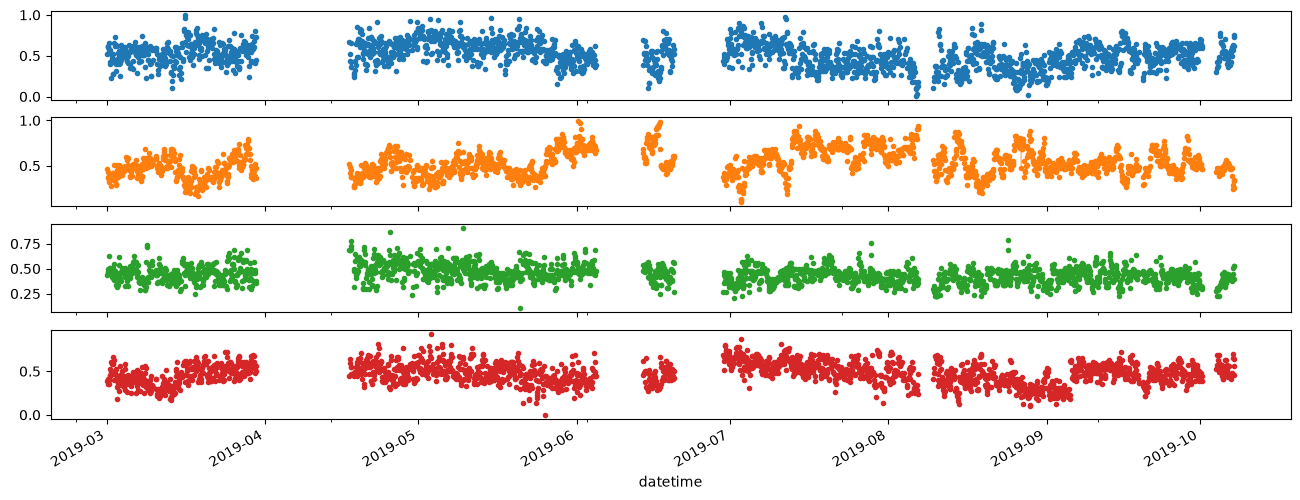

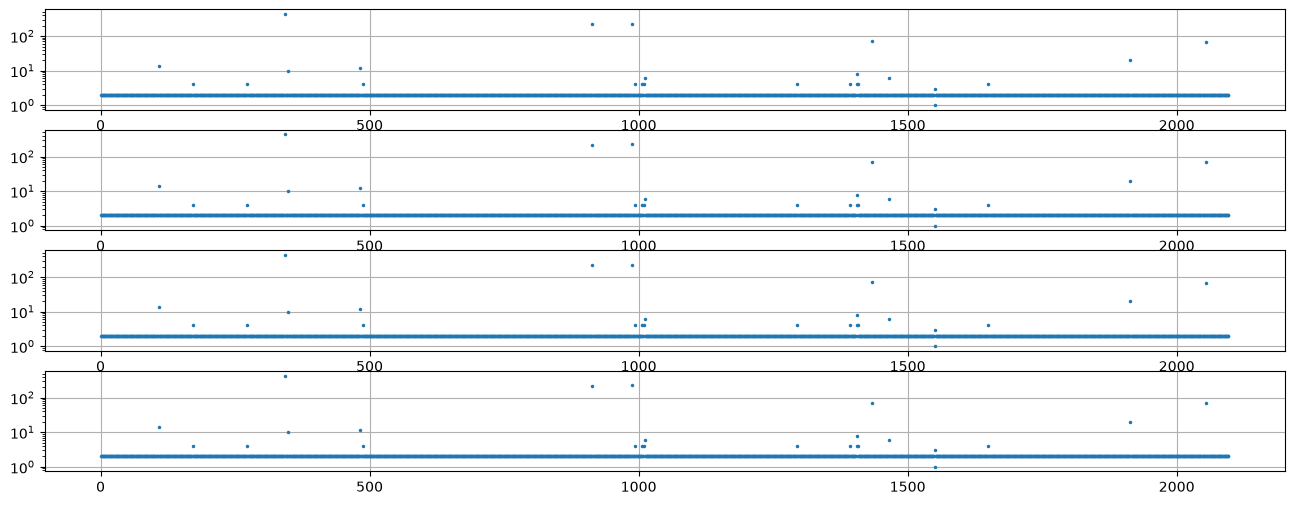

In [32]:
# построим часть фичей с большим количество пропусков
LAB_COLS = list(x_train_raw.keys())[12:]
x_train_raw[LAB_COLS].plot(subplots=True, figsize=(16, 6), sharex=True, lw=0.6, legend=False, marker=".")
plt.show()

# построим временные шаги (в часах)
fig, axes = plt.subplots(len(LAB_COLS), 1, figsize=(16, 6), sharex=False)
for ax, col in zip(axes, LAB_COLS):
    ts = pd.Series(x_train_raw.index[x_train_raw[col].notna()]).drop_duplicates().sort_values()
    tsteps = ts.diff().dt.total_seconds().div(3600)
    ax.plot(tsteps.values, ".", ms=3)
    ax.set_yscale("log")
    ax.grid()
plt.show()

In [34]:
# таргет и фичи 12-15 имеют шаг 2 часа, сравним их между собой
k = list(x_train_raw.keys())[12:]
print(x_train_raw.index)
print(y_train_raw.index)

DatetimeIndex(['2019-03-01 00:01:00', '2019-03-01 00:02:00',
               '2019-03-01 00:03:00', '2019-03-01 00:04:00',
               '2019-03-01 00:05:00', '2019-03-01 00:06:00',
               '2019-03-01 00:07:00', '2019-03-01 00:08:00',
               '2019-03-01 00:09:00', '2019-03-01 00:10:00',
               ...
               '2019-10-07 19:49:00', '2019-10-07 19:50:00',
               '2019-10-07 19:51:00', '2019-10-07 19:52:00',
               '2019-10-07 19:53:00', '2019-10-07 19:54:00',
               '2019-10-07 19:55:00', '2019-10-07 19:56:00',
               '2019-10-07 19:57:00', '2019-10-07 19:58:00'],
              dtype='datetime64[us]', name='datetime', length=319546, freq=None)
DatetimeIndex(['2019-03-13 17:00:00', '2019-03-13 21:00:00',
               '2019-03-14 01:00:00', '2019-03-14 05:00:00',
               '2019-03-14 09:00:00', '2019-03-14 13:00:00',
               '2019-03-14 17:00:00', '2019-03-14 19:00:00',
               '2019-03-14 21:00:00', '2019-0

**Наблюдения**: 
- Данные содержат несколько интервалов, разделённых большими пропусками.
- Внутри каждого интервала у фичей могут присутствовать пропуски по 1 отсчёту
- Индексы фичей 12-15 и таргета смещены на 1 час (шага 2 часа, чётные и нечётные соответственно)

In [37]:
# проинтерполируем 1-точечные пропуски и приведём телеметрию к минутной сетке
x_train = x_train_raw.sort_index()
x_train = x_train[~x_train.index.duplicated(keep="first")].asfreq("1min")
x_test = x_test_raw.sort_index()
x_test = x_test[~x_test.index.duplicated(keep="first")].asfreq("1min")

x_train[BASE_COLS] = x_train[BASE_COLS].interpolate(method="time", limit=1, limit_area="inside")
x_test[BASE_COLS] = x_test[BASE_COLS].interpolate(method="time", limit=1, limit_area="inside")

y_train = y_train_raw.sort_index()
y_train = y_train[~y_train.index.duplicated(keep="first")]
y_train = y_train[y_train["target"] > 0]
y_test = y_test_raw.sort_index()
y_test = y_test[~y_test.index.duplicated(keep="first")]
y_test = y_test[y_test["target"] > 0]


**Промежуточный вывод**: согласно выбраной стратегии мы работает на равномерно распределённой временной сетке (шаг 2 часа), соответственно, осталось привести фичи 0-11 к заданной сетке. Это будет сделано ниже за счёт оконных характеристик (длина окна 2 часа).

**Наблюдения**:
- Фичи нестационарны, например, пожно наблюдать долгие провалы вниз, что явно меняет среднее
- В фичах встречаются выбросы


# Инжиниринг признаков для временных рядов 

**Идея**: используем оконные характеристики
- Медиана
- Среднее
- Среднеквадратичное отклонение

Не бдуем рассматривать:
- Минимум
- Максимум

Такой выбор обусловлен тем, что в данных наблюдаются выбросы, значит экстремальные характиристики будут значительно искажены

In [ ]:
WINDOW = 120
MIN_PERIODS = 60
STATS = ("mean", "median", "std")


def build_window_features(tel, raw_tel, times):
    raw_tel = raw_tel[~raw_tel.index.duplicated(keep="first")].sort_index()
    times = pd.DatetimeIndex(times)
    end = times - pd.Timedelta(minutes=1)
    out = {}
    for c in BASE_COLS: # сетка одна минута, считаем 2х часовые окна
        roll = tel[c].rolling(WINDOW, min_periods=MIN_PERIODS)
        for stat in STATS:
            out[f"{c}_{stat}"] = getattr(roll, stat)().reindex(end).values
    for c in LAB_COLS: # сетка 2 часа
        out[f"{c}_lag60"] = tel[c].shift(60).reindex(times).values  # ранее описанный сдвиг на -1 час
        obs_time = pd.Series(raw_tel.index, index=raw_tel.index).where(raw_tel[c].notna()).ffill()
        last = obs_time.reindex(times - pd.Timedelta(minutes=60), method="ffill").values
        out[f"{c}_age60"] = (times - last).total_seconds() / 60     # дельта по времени
    return pd.DataFrame(out, index=times)


Xw_train = build_window_features(x_train, x_train_raw, y_train.index)   # синтезированные фичи на трейне
Xw_test = build_window_features(x_test, x_test_raw, y_test.index)       # синтезированные фичи на тесте
Xw_all = pd.concat([Xw_train, Xw_test]).sort_index()
print("window features:", Xw_all.shape)


window features: (2090, 44)


Количество синтезированнх фичей 44, при этом они должны быть сильно связаны между собой.

Так, для удаления избыточности применим PCA - возьмём первые 15 компонент

In [40]:
Xw_train_all = Xw_all.loc[y_train.index]
Xw_test_all = Xw_all.loc[y_test.index]
med = Xw_train_all.median()
Xw_train_all = Xw_train_all.fillna(med)
Xw_test_all = Xw_test_all.fillna(med)

scaler = StandardScaler().fit(Xw_train_all.to_numpy())
Z_train = scaler.transform(Xw_train_all.to_numpy())
Z_test = scaler.transform(Xw_test_all.to_numpy())
pca = PCA(n_components=15).fit(Z_train) # строим PCA на тренировочной выборке
PC_train = pca.transform(Z_train)
PC_test = pca.transform(Z_test)

Что бы исключить накопление ошибки, добавим таргет (реальные лабораторные замеры) с лагом 2 часа (предыдущий сэмпл)

Фичи были построены таким образом, что в обучении можно использовать только сэмплы, для которых существует значение на 1 лаге, соответственно для обучения отберём такие сэмплы

In [ ]:
def target_history(times, target):  # таргет с лагом 1 в качестве фичи
    s = target.reindex(times)
    out = {}
    out[f"target_lag1"] = s.shift(1)
    return pd.DataFrame(out, index=times)

all_targets = pd.concat([y_train, y_test]).sort_index()
all_targets = all_targets[~all_targets.index.duplicated(keep="first")]
all_times = all_targets.index.sort_values()
steps = all_times.to_series().diff().dt.total_seconds().div(60).fillna(0)
block_id = (steps != 120).cumsum()
hist_parts = []
for _, block in all_times.to_series().groupby(block_id.values):
    block = pd.DatetimeIndex(block.values)
    hist_parts.append(target_history(block, all_targets["target"].reindex(block)))
hist_all = pd.concat(hist_parts).sort_index()
hist_cols = list(hist_all.columns)

X_train = np.hstack([PC_train, hist_all.loc[y_train.index].to_numpy()])
X_test = np.hstack([PC_test, hist_all.loc[y_test.index].to_numpy()])
feature_names = [f"PC{i+1}" for i in range(15)] + hist_cols
y_train_arr = y_train["target"].to_numpy()
y_test_arr = y_test["target"].to_numpy()
prev_train = hist_all.loc[y_train.index, "target_lag1"].to_numpy()
prev_test = hist_all.loc[y_test.index, "target_lag1"].to_numpy()
mask_train = np.isfinite(prev_train) & np.isfinite(X_train).all(axis=1) # выбираем только сэмплы, для которых определено пред. значение
mask_test = np.isfinite(prev_test) & np.isfinite(X_test).all(axis=1)

# Построение прогнозных моделей 

Мы имеем всего 1700 точек таргета (даже ещё меньше если учитывать выбраный способ бороться с большими пропусками), поэтому NN методы не подойдут - большой риск переобучения. Также в силу построения наших фичей (нелинейны и могут быть скоррелированы) SARIMAX также не подойдёт. Таким образом, в качестве моделей были выбраны:
- Градиентный бустинг
- Случайный лес
- Линейная регрессия с L2 регуляризацией

In [73]:
def metrics(y, p):
    e = y - p
    mae = np.mean(np.abs(e))
    rmse = np.sqrt(np.mean(e ** 2))
    mape = np.mean(np.abs(e / y)) * 100
    wape = np.sum(np.abs(e)) / np.sum(np.abs(y)) * 100
    return mae, rmse, mape, wape


models = {
    "LightGBM": LGBMRegressor(random_state=0, verbosity=-1),    # градиентный бустинг, дефолтные параметры, зафиксируем сид для воспроизводимости
    "RandomForest": RandomForestRegressor(random_state=0),      # случайный лес, дефолтные параметры
    "Ridge": RidgeCV(),                                         # линейная регрессия, L2 регуляризация
}
for name, model in models.items():
    model.fit(X_train[mask_train], y_train_arr[mask_train])


In [77]:
# результаты на тренировочной выборке
preds = {}
for name, model in models.items():
    preds[name] = np.full(len(y_train_arr), np.nan)
    preds[name][mask_train] = model.predict(X_train[mask_train])

print(f"{" " * 15}\tMAE\tRMSE\tMAPE\tWAPE")
for name, p in preds.items():
    m = metrics(y_train_arr[mask_train], p[mask_train])
    print(f"{name:14s}\t{m[0]:2.4f}\t{m[1]:2.4f}\t{m[2]:2.2f}\t{m[3]:2.2f}")

               	MAE	RMSE	MAPE	WAPE
LightGBM      	0.0208	0.0267	9.55	8.14
RandomForest  	0.0214	0.0277	9.94	8.39
Ridge         	0.0555	0.0712	25.66	21.74


In [78]:
# посмотрим на результаты на тестовой выборке, чтобы убедится в адекватности модели
preds = {}
for name, model in models.items():
    preds[name] = np.full(len(y_test_arr), np.nan)
    preds[name][mask_test] = model.predict(X_test[mask_test])

print(f"{" " * 15}\tMAE\tRMSE\tMAPE\tWAPE")
for name, p in preds.items():
    m = metrics(y_test_arr[mask_test], p[mask_test])
    print(f"{name:14s}\t{m[0]:2.4f}\t{m[1]:2.4f}\t{m[2]:2.2f}\t{m[3]:2.2f}")

               	MAE	RMSE	MAPE	WAPE
LightGBM      	0.0535	0.0688	28.41	25.50
RandomForest  	0.0541	0.0690	29.99	25.76
Ridge         	0.0519	0.0679	27.84	24.70


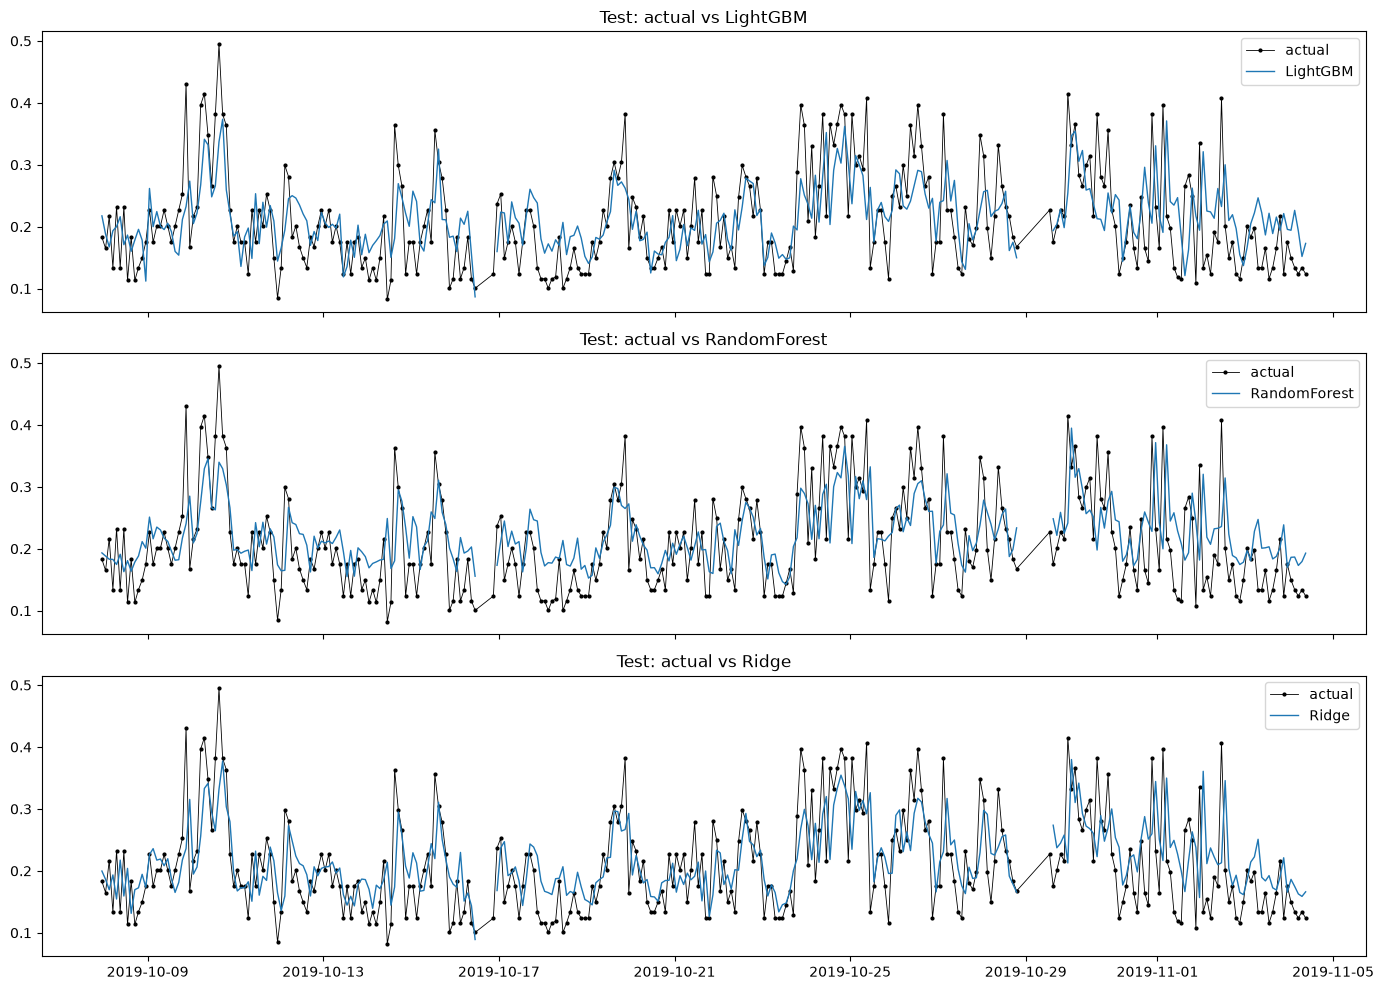

In [ ]:
# визуализация предсказаний
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, name in zip(axes, ["LightGBM", "RandomForest", "Ridge"]):
    ax.plot(y_test.index, y_test_arr, "o-", ms=2, lw=0.6, color="black", label="actual")
    ax.plot(y_test.index, preds[name], lw=1.0, label=name)
    ax.set_title(f"Test: actual vs {name}")
    ax.legend()
plt.tight_layout()
plt.show()


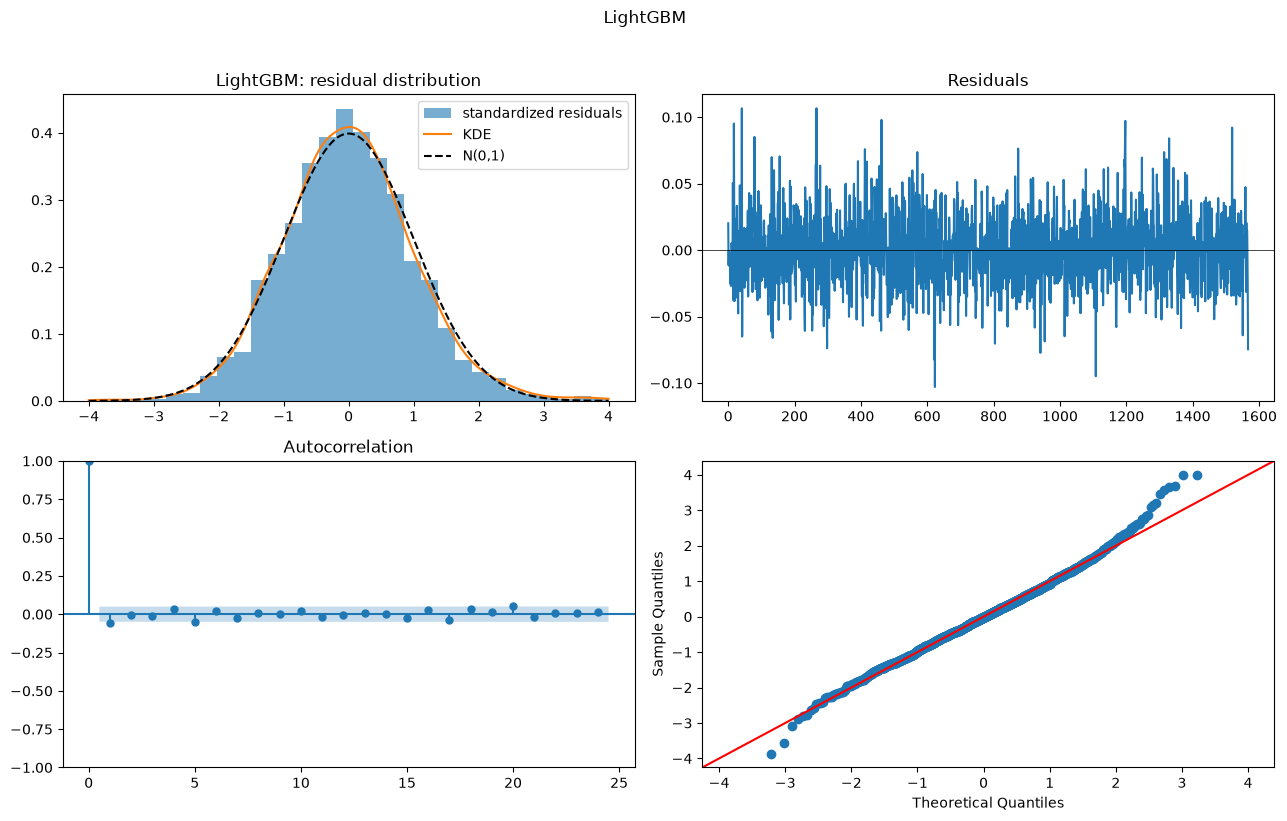

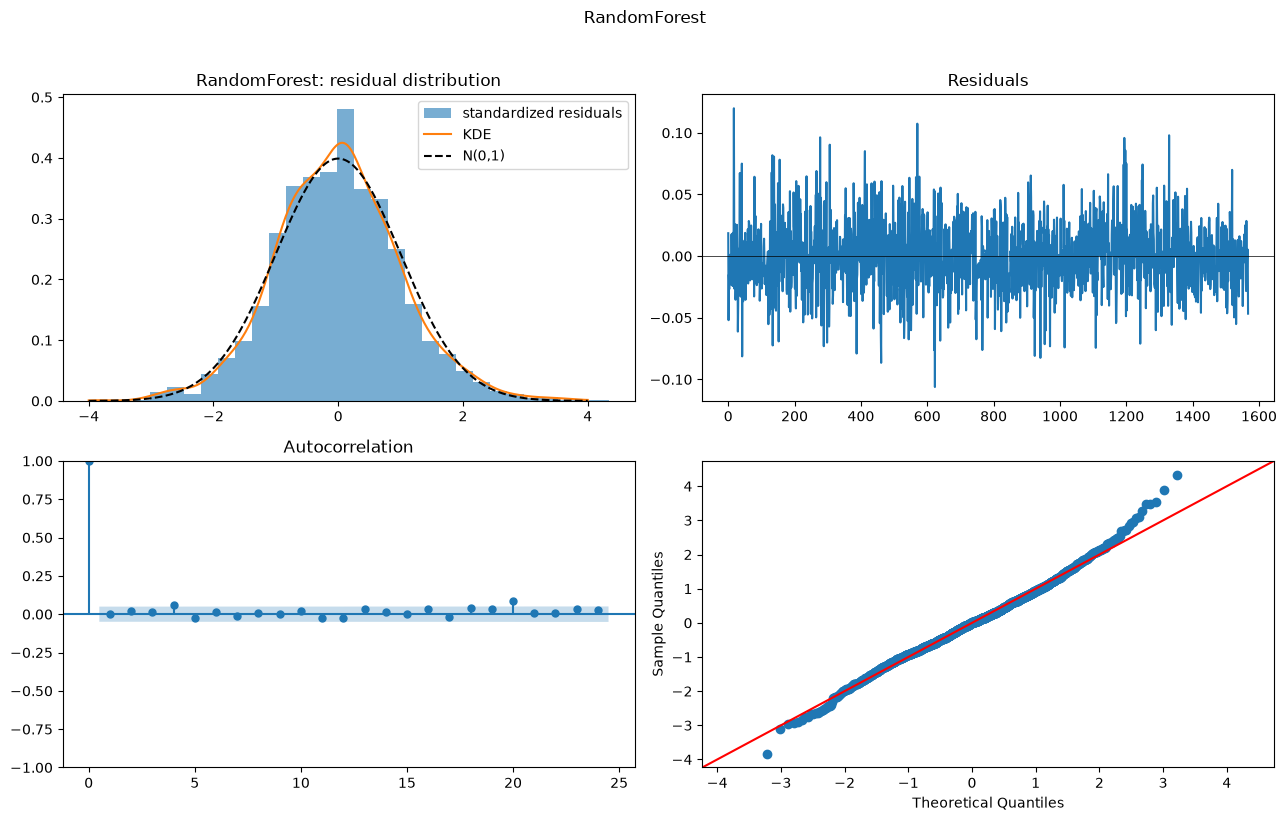

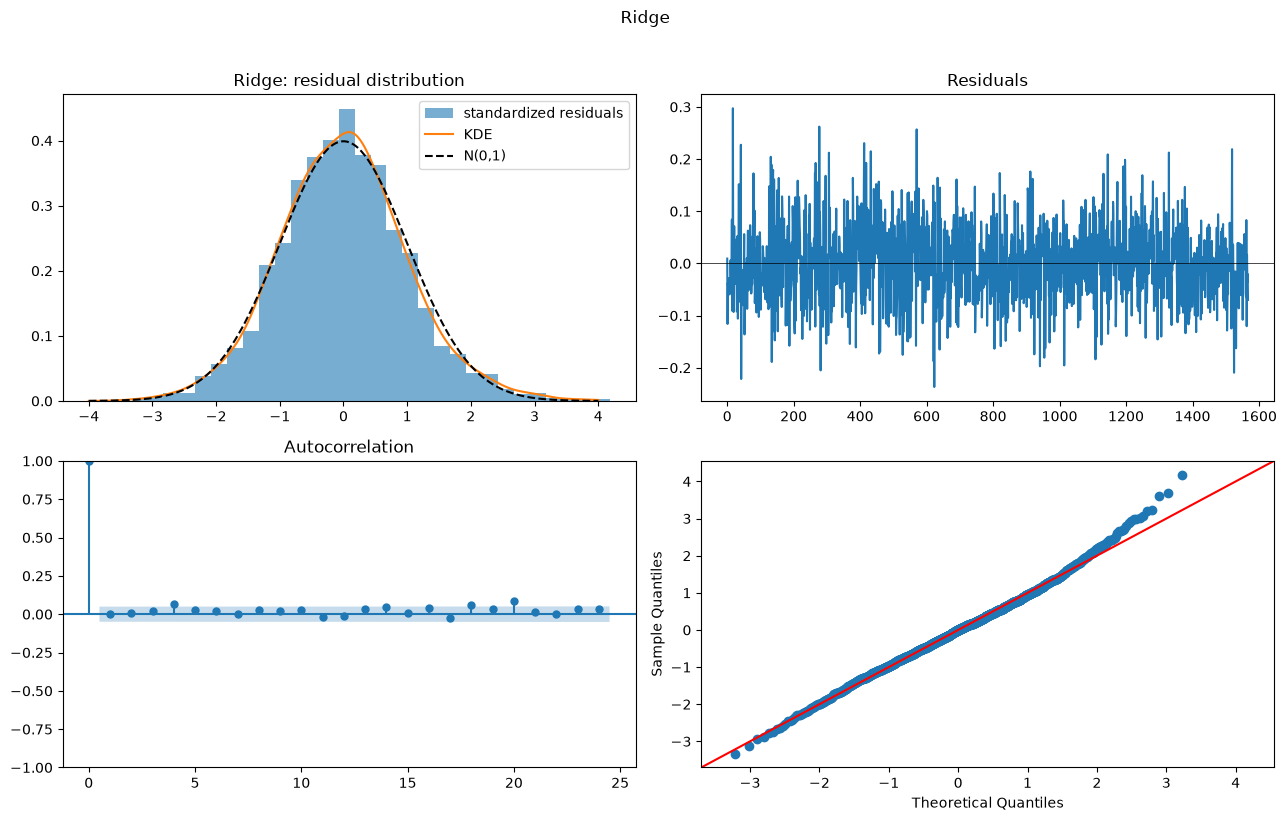

In [86]:
X_fit = X_train[mask_train]
prev_fit = prev_train[mask_train]
y_fit = y_train_arr[mask_train]

resid_rows = {}
for name in ["LightGBM", "RandomForest", "Ridge"]:
    pred_fit = models[name].predict(X_fit)
    resid = y_fit - pred_fit
    z = (resid - resid.mean()) / resid.std(ddof=1)  # нормализируем остатки

    fig, axs = plt.subplots(2, 2, figsize=(13, 8))
    axs[0, 0].hist(z, bins=30, density=True, alpha=0.6, label="standardized residuals")
    grid = np.linspace(-4, 4, 300)
    axs[0, 0].plot(grid, stats.gaussian_kde(z)(grid), label="KDE")
    axs[0, 0].plot(grid, stats.norm.pdf(grid), "k--", label="N(0,1)")
    axs[0, 0].legend()
    axs[0, 0].set_title(f"{name}: residual distribution")
    axs[0, 1].plot(resid)
    axs[0, 1].axhline(0, color="black", lw=0.5)
    axs[0, 1].set_title("Residuals")
    plot_acf(resid, ax=axs[1, 0], lags=24)
    qqplot(z, line="45", ax=axs[1, 1])
    fig.suptitle(name, y=1.02)
    plt.tight_layout()
    plt.show()


Для всех предложенных моделей можно считать, что остатки распределены нормально с постоянной дисперсией (свойство гомоскедастичности).

При этом у всех моделей имеется слабая автокорреляция остатков (около 4 и 20 лагов), это может быть объяснено тем, как мы строили фичи, например, 15 главных компонент не хватило или же требовались дополнительные лаги таргета

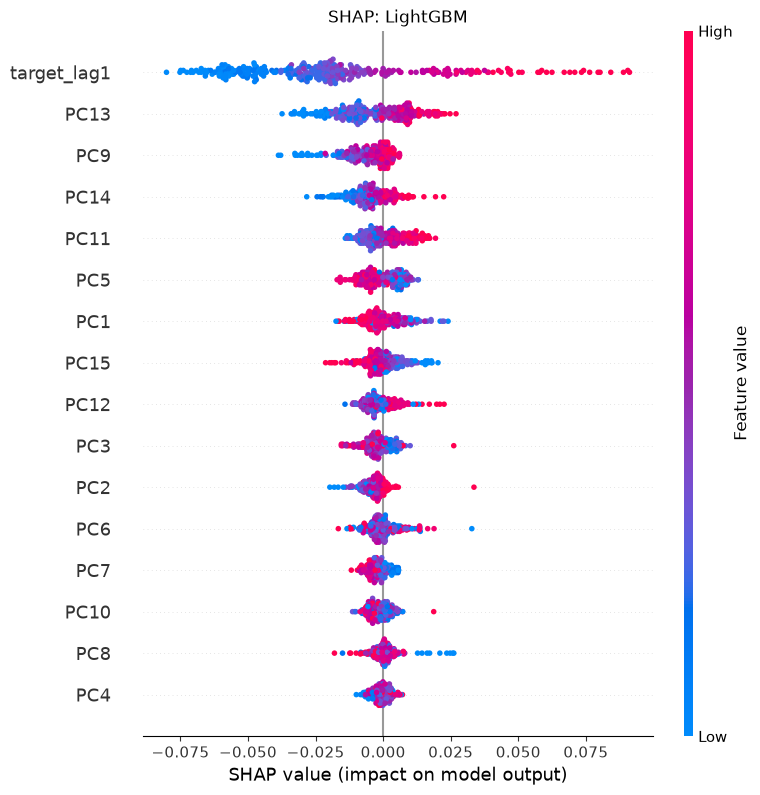

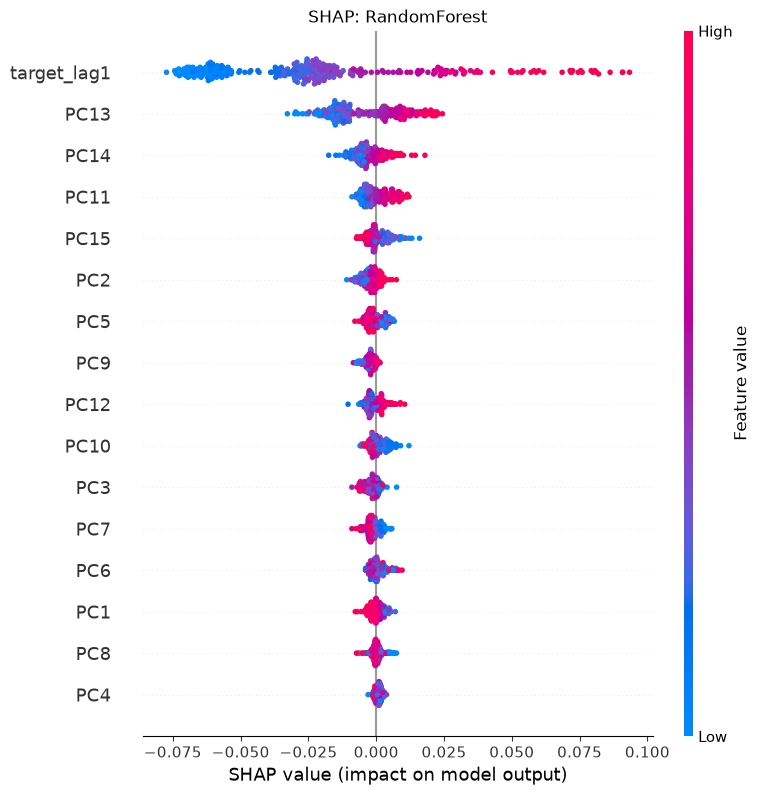

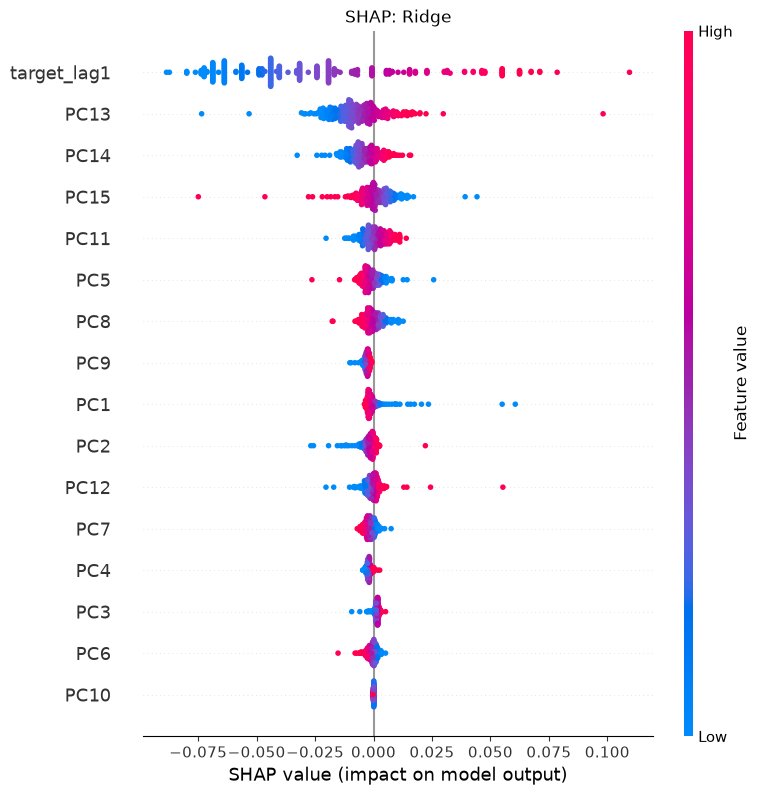

In [87]:
X_shap = X_test[mask_test]
for name, model in models.items():
    if name == "Ridge":
        explainer = shap.LinearExplainer(model, X_train[mask_train])
    else:
        explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_shap)
    shap.summary_plot(sv, X_shap, feature_names=feature_names, show=False, plot_type="dot")
    plt.title(f"SHAP: {name}")
    plt.show()


SHAP частично подтверждает гипотезу о том, что часть отброшеных коспонент могла нести информацию - главные компоненты не отсортированы по значимости

**Выводы**: полученные модели являются статистически адекватными, что подтверждается тестовой выборкой (как метрики, так и визульный анализ), а также анализом остатков. Однако при этом остаток остатков раскрыл определённые недостатки моделей:
- Несмотря на построенные фичи, таргет на лаге 1 оказался куда более значимым
- SHAP и слабая автокорреляция остатков указывают на то, что выбор 15 главных компонент было не самым правильным решением, т.к. не учитывалось влияние на таргет, соответственно это привело к некотрой потере информации